# Manuscript figures for comparing embedded and staged data-driven closure modeling approach

In [1]:
from __future__ import annotations

import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

from pathlib import Path
import json
import warnings

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import jax.numpy as jnp
import jax.nn as jnn
import jax.random as jr
import equinox as eqx

from siqr_observation_data import (
    ObservationConfig,
    calibration_scenario,
    validation_scenarios,
    simulate_true_siqr,
    xi_f_nondim,
)

Overall config for the document

In [2]:
STUDY_DIR = Path("data/study_replicates")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

NUM_REPLICATES_REQUESTED = 50

SAVE_DPI = 600
SAVE_FORMATS = ["png" ]#, "pdf"]

STATE_NAMES = ["Susceptible", "Infectious", "Quarantined", "Removed"]
STATE_SYMBOLS = [r"$s(t)$", r"$i(t)$", r"$q(t)$", r"$r(t)$"]

# # =============================================================================
# # Matplotlib LaTeX text rendering
# # =============================================================================

# import matplotlib as mpl

# mpl.rcParams.update(
#     {
#         "text.usetex": True,
#         "font.family": "serif",
#         "font.serif": ["Computer Modern Roman"],
#         "axes.unicode_minus": False,
#         "pdf.fonttype": 42,
#         "ps.fonttype": 42,
#     }
# )

### Utility functions

In [3]:
def save_figure(fig, stem: str):
    """
    Save a matplotlib figure under FIG_DIR with all requested formats.
    """
    path = f"{FIG_DIR}/{stem}.png"
    fig.savefig(path, bbox_inches="tight", transparent=True, dpi=600)
    print(f"Saved {path}")


def npz_scalar(z, key, default=None):
    if key not in z.files:
        return default
    arr = np.asarray(z[key])
    if arr.shape == ():
        return arr.item()
    return arr


def load_json(path: Path):
    with open(path, "r") as f:
        return json.load(f)


def rep_dir(r: int) -> Path:
    return STUDY_DIR / f"rep_{r:03d}"


def file_success_npz(path: Path, key: str = "success") -> bool:
    if not path.exists():
        return False
    try:
        z = np.load(path, allow_pickle=True)
        if key not in z.files:
            return False
        return bool(np.asarray(z[key]).item())
    except Exception:
        return False

def discover_replicates(num_requested: int = NUM_REPLICATES_REQUESTED):
    """
    Discover available replicate IDs and classify by available successful outputs.
    """
    all_reps = []
    embedded_reps = []
    enkf_reps = []
    staged_reps = []

    for r in range(num_requested):
        rd = rep_dir(r)
        if not rd.exists():
            continue

        all_reps.append(r)

        if file_success_npz(rd / "embedded_closure.npz"):
            embedded_reps.append(r)

        if (rd / "enkf_result.npz").exists() and (rd / "enkf_summary.json").exists():
            try:
                s = load_json(rd / "enkf_summary.json")
                if bool(s.get("success", False)):
                    enkf_reps.append(r)
            except Exception:
                pass

        if file_success_npz(rd / "staged_closure.npz"):
            staged_reps.append(r)

    return {
        "all": all_reps,
        "embedded": embedded_reps,
        "enkf": enkf_reps,
        "staged": staged_reps,
        "both_state_methods": sorted(set(embedded_reps).intersection(staged_reps)),
    }

In [4]:
# =============================================================================
# Metric plotting and table setup
# =============================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

try:
    import seaborn as sns
except ImportError as exc:
    raise ImportError(
        "These plotting cells require seaborn. Install seaborn or replace "
        "sns.violinplot with matplotlib equivalents."
    ) from exc


TABLE_DIR = Path("tables")
TABLE_DIR.mkdir(parents=True, exist_ok=True)

METHOD_LABELS = {
    "embedded": "Embedded",
    "staged": "STAGED DDCM",
}

METHOD_ORDER = ["Embedded", "STAGED DDCM"]

METHOD_PALETTE = {
    "Embedded": "C6",
    "STAGED DDCM": "#10a8e0",
}


def tex_escape(s):
    """
    Minimal LaTeX escaping for table text.
    """
    s = str(s)
    replacements = {
        "&": r"\&",
        "%": r"\%",
        "$": r"\$",
        "#": r"\#",
        "_": r"\_",
    }

    for old, new in replacements.items():
        s = s.replace(old, new)

    return s


def tex_sci(x, sig=3):
    """
    Format a number as LaTeX scientific notation.
    """
    x = float(x)

    if not np.isfinite(x):
        return r"\(\infty\)"

    if x == 0:
        return r"\(0\)"

    exponent = int(np.floor(np.log10(abs(x))))
    mantissa = x / (10 ** exponent)

    return rf"\({mantissa:.{sig - 1}f}\times 10^{{{exponent}}}\)"


def tex_pm(mean, std, sig=3):
    """
    Format mean ± std in LaTeX.
    """
    mean = float(mean)
    std = float(std)

    if not np.isfinite(mean) or not np.isfinite(std):
        return r"\(\infty\)"

    if mean == 0 and std == 0:
        return r"\(0 \pm 0\)"

    return rf"{tex_sci(mean, sig=sig)} \( \pm \) {tex_sci(std, sig=sig)}"


def nanmean_std(x):
    x = np.asarray(x, dtype=float)
    return float(np.nanmean(x)), float(np.nanstd(x))


def write_tex_table(path, lines):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    text = "\n".join(lines) + "\n"

    with open(path, "w") as f:
        f.write(text)

    print(f"Saved {path}")

    return text


def file_success_npz_local(path, key="success"):
    path = Path(path)

    if not path.exists():
        return False

    try:
        z = np.load(path, allow_pickle=True)

        if key not in z.files:
            return False

        return bool(np.asarray(z[key]).item())

    except Exception:
        return False


def get_common_successful_training_reps(num_requested=NUM_REPLICATES_REQUESTED):
    """
    Replicates with both successful embedded_closure.npz and staged_closure.npz.
    """
    common = []

    for r in range(num_requested):
        rd = rep_dir(r)

        embedded_ok = file_success_npz_local(rd / "embedded_closure.npz")
        staged_ok = file_success_npz_local(rd / "staged_closure.npz")

        if embedded_ok and staged_ok:
            common.append(r)

    return common

In [5]:
# =============================================================================
# Violin-only plotting helper
# =============================================================================

def violinplot_only( data, *, x, y, hue, order, hue_order, palette, ax, inner="quartile" ):
    """
    Seaborn violinplot wrapper with compatibility for different seaborn versions.
    """
    try:
        sns.violinplot( data=data, x=x, y=y, hue=hue, order=order, hue_order=hue_order, palette=palette, 
                       inner=inner, cut=0, linewidth=1.0, density_norm="width", ax=ax,)
    except TypeError:
        sns.violinplot( data=data, x=x, y=y, hue=hue, order=order, hue_order=hue_order, palette=palette, inner=inner, cut=0, linewidth=1.0, scale="width", ax=ax )

In [6]:
reps = discover_replicates()
reps

{'all': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49],
 'embedded': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49],
 'enkf': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40,
  41,
  42,
  43,
  44,
  45,
  46,
  47,
  48,
  49],
 'staged': [0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16

In [7]:
print(f"Study directory: {STUDY_DIR.resolve()}")
print(f"All replicate dirs found:          {len(reps['all'])}")
print(f"Successful embedded closures:      {len(reps['embedded'])}")
print(f"Successful EnKF outputs:           {len(reps['enkf'])}")
print(f"Successful staged closures:        {len(reps['staged'])}")
print(f"Successful embedded and staged:    {len(reps['both_state_methods'])}")

if len(reps["all"]) == 0:
    raise RuntimeError(f"No replicate directories found under {STUDY_DIR}")

Study directory: /ceeGPFS/fgs/tporton/ddcm/embedded-staged-comparison-code/data/study_replicates
All replicate dirs found:          50
Successful embedded closures:      50
Successful EnKF outputs:           50
Successful staged closures:        50
Successful embedded and staged:    50



## Load a reference observation dataset

We use replicate 0, if available, to draw Figure 3 and to recover the observation
configuration used for time grids and true trajectories.


In [8]:
REF_REP = reps["all"][0]
obs_ref = np.load(rep_dir(REF_REP) / "observations.npz", allow_pickle=True)

t_obs_ref = np.asarray(obs_ref["t_obs"])
d_ref = np.asarray(obs_ref["d"])              # shape: (4, N)
d_ref_time_major = d_ref.T                    # shape: (N, 4)
y_true_ref = np.asarray(obs_ref["y_true"])    # shape: (4, N)
y_true_ref_time_major = y_true_ref.T
xi_true_ref = np.asarray(obs_ref["xi_true"])
H_true_ref = np.asarray(obs_ref["H_true"])
obs_var_ref = float(np.asarray(obs_ref["obs_var"]))
params_ref = np.asarray(obs_ref["params"], dtype=float)

print(f"Reference replicate: {REF_REP:03d}")
print(f"t_obs shape:         {t_obs_ref.shape}")
print(f"d shape:             {d_ref.shape}")
print(f"y_true shape:        {y_true_ref.shape}")
print(f"obs_var:             {obs_var_ref}")
print(f"params:              {params_ref}")

# %%
def get_observation_config_from_obs(obs_npz) -> ObservationConfig:
    """
    Reconstruct ObservationConfig from observations.npz when possible.
    Falls back to ObservationConfig(obs_var=obs_var).
    """
    if "config_json" not in obs_npz.files:
        return ObservationConfig(obs_var=float(np.asarray(obs_npz["obs_var"])))

    raw = np.asarray(obs_npz["config_json"]).item()
    parsed = json.loads(raw)
    config_dict = parsed["config"]

    return ObservationConfig(**config_dict)


obs_config = get_observation_config_from_obs(obs_ref)
obs_config

Reference replicate: 000
t_obs shape:         (801,)
d shape:             (4, 801)
y_true shape:        (4, 801)
obs_var:             1e-06
params:              [0.15  0.013 0.01 ]


ObservationConfig(N_total=2000000, I0=500, Q0=10, R0=10, N_days=200.0, step=0.25, step_obs=0.25, obs_var=1e-06, xi_threshold_count=300000.0, xi_transition_width_fraction=0.05, method='RK45')

# Visualizing the states of the true system

Saved figures/true_system_dynamics.png


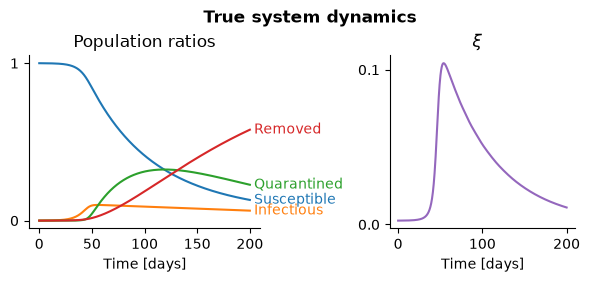

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(6, 3), width_ratios=[1,0.8])

ax = axs[0]
for j, sn in enumerate(STATE_NAMES):
    ax.plot( t_obs_ref, y_true_ref[j, :], f"C{j}")#, linewidth=1 )
    ax.annotate(sn, (t_obs_ref[-1]*1.02, y_true_ref[j,-1]), color=f'C{j}', va='center',annotation_clip=False)

ax.set_xlabel("Time [days]")
ax.set_title("Population ratios")
ax.set_yticks([0,1])

ax = axs[1]
ax.plot(t_obs_ref, xi_true_ref, "C4")
ax.set_xlabel("Time [days]")
ax.set_title(r"$\xi$", rotation=0, ha='right')
ax.set_yticks([0,0.1])

for ax in axs:
    ax.spines[['top','right']].set_visible(False)

fig.suptitle('True system dynamics', y=0.925, x=0.525, fontweight='bold')
fig.tight_layout()
save_figure(fig, "true_system_dynamics")

# Embedded and STAGED state trajectories across replicates

This uses:

- `embedded_closure.npz`: `y`
- `staged_closure.npz`: `y`

and compares them against the reference noisy observations and true trajectory.

In [10]:
common_reps = reps["both_state_methods"]

if len(common_reps) == 0:
    raise RuntimeError(
        "No replicates have both embedded_closure.npz and staged_closure.npz marked successful."
    )

print(f"Using {len(common_reps)} successful embedded+staged replicates.")

# %%
def load_method_trajectories(rep_ids, closure_filename: str):
    ys = []
    xis = []
    ok_reps = []

    for r in rep_ids:
        path = rep_dir(r) / closure_filename
        if not file_success_npz(path):
            continue

        z = np.load(path, allow_pickle=True)

        y = np.asarray(z["y"], dtype=float)
        xi = np.asarray(z["xi"], dtype=float)

        if y.shape[0] != len(t_obs_ref):
            warnings.warn(
                f"Skipping rep {r:03d}; {closure_filename} has y shape {y.shape}, "
                f"expected first dimension {len(t_obs_ref)}."
            )
            continue

        ys.append(y)
        xis.append(xi)
        ok_reps.append(r)

    return np.asarray(ys), np.asarray(xis), ok_reps

embedded_y, embedded_xi, embedded_ok = load_method_trajectories(
    common_reps,
    "embedded_closure.npz",
)
staged_y, staged_xi, staged_ok = load_method_trajectories(
    common_reps,
    "staged_closure.npz",
)

print(f"Embedded loaded trajectories: {embedded_y.shape}")
print(f"Staged loaded trajectories:   {staged_y.shape}")

Using 50 successful embedded+staged replicates.
Embedded loaded trajectories: (50, 801, 4)
Staged loaded trajectories:   (50, 801, 4)


Saved figures/embedded_vs_staged_replicates.png


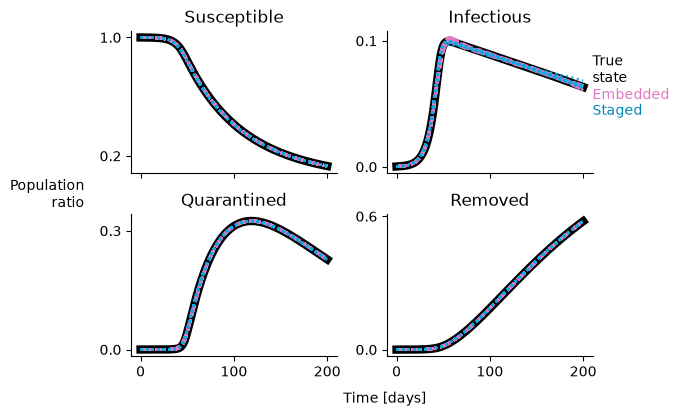

In [11]:
fig, axs = plt.subplots( 2, 2, figsize=(6, 4), sharex=True)

for ax, state_name, embedded_state, staged_state, true_state in zip(axs.flatten(), STATE_NAMES, embedded_y.T, staged_y.T, y_true_ref):
    ax.plot(t_obs_ref, true_state, 'k', lw=6)
    ax.plot(t_obs_ref, embedded_state, '--', color='C6', lw=2)
    ax.plot(t_obs_ref, staged_state, ':', color="#10a8e0")
    ax.spines[['top','right']].set_visible(False)
    ax.set_title(state_name)
    ax.set_yticks([ax.get_yticks()[1], ax.get_yticks()[-2]])

axs[0,1].annotate('True\nstate', (210,0.09), va='top', ha='left', annotation_clip=False)
axs[0,1].annotate('Embedded', (210,0.0625), va='top', ha='left', annotation_clip=False, color='C6')
axs[0,1].annotate('Staged', (210,0.05), va='top', ha='left', annotation_clip=False, color="#0087b8")

fig.text(0.5,-.02,'Time [days]', ha='center')
fig.text(0,0.5,'Population\nratio', ha='right', va='center')
fig.tight_layout()

save_figure(fig, "embedded_vs_staged_replicates")

# Figure 5: learned closures across replicates

This compares learned closure trajectories against the true, unobservable closure
used to generate the synthetic data.


Saved figures/learned_closures.png


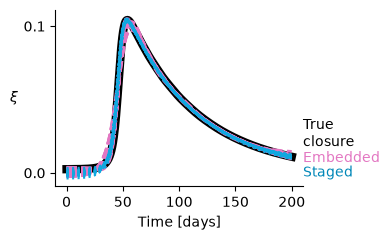

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(4, 2.5))


ax.plot(t_obs_ref, xi_true_ref, 'k', lw=6)
ax.plot(t_obs_ref, embedded_xi.T, '--', color='C6', lw=2)
ax.plot(t_obs_ref, staged_xi.T, ':', color='#10a8e0')
ax.spines[['top','right']].set_visible(False)
ax.set_yticks([ax.get_yticks()[1], ax.get_yticks()[-2]])
ax.set_xlabel('Time [days]')
ax.set_ylabel(r'$\xi$', rotation=0, ha='right', va='center')

ax.annotate('True\nclosure', (210,0.015), va='bottom', ha='left', annotation_clip=False)
ax.annotate('Embedded', (210,0.01), va='center', ha='left', annotation_clip=False, color='C6')
ax.annotate('Staged', (210,0.005), va='top', ha='left', annotation_clip=False, color="#0087b8")


fig.tight_layout()
save_figure(fig, "learned_closures")

In [13]:
# =============================================================================
# Build calibration held-out test-loss and closure-RMSE dataframe
# =============================================================================

def get_test_loss_from_closure(r: int, method: str):
    """
    Load saved held-out test loss for one replicate and one method.

    method:
        "embedded" or "staged"

    Returns:
        Saved observation-space likelihood-scaled test loss.
    """
    if method not in ["embedded", "staged"]:
        raise ValueError("method must be 'embedded' or 'staged'.")

    closure_file = rep_dir(r) / f"{method}_closure.npz"

    if not closure_file.exists():
        return np.nan

    z = np.load(closure_file, allow_pickle=True)

    if "test_loss" not in z.files:
        return np.nan

    return float(np.asarray(z["test_loss"]))


def closure_rmse_idx(xi_pred, xi_true, idx):
    """
    Closure RMSE on selected time indices.
    """
    xi_pred = np.asarray(xi_pred, dtype=float)
    xi_true = np.asarray(xi_true, dtype=float)
    idx = np.asarray(idx, dtype=int)

    residual = xi_pred[idx] - xi_true[idx]

    if not np.all(np.isfinite(residual)):
        return np.nan

    return float(np.sqrt(np.mean(residual ** 2)))


def get_test_closure_rmse_from_closure(r: int, method: str):
    """
    Compute held-out test closure RMSE for one replicate and one method.

    Uses:
        closure["xi"]
        closure["xi_true"]
        closure["test_idx"]

    This is available only because the study is synthetic.
    """
    if method not in ["embedded", "staged"]:
        raise ValueError("method must be 'embedded' or 'staged'.")

    closure_file = rep_dir(r) / f"{method}_closure.npz"

    if not closure_file.exists():
        return np.nan

    z = np.load(closure_file, allow_pickle=True)

    xi_pred = np.asarray(z["xi"], dtype=float)
    xi_true = np.asarray(z["xi_true"], dtype=float)
    test_idx = np.asarray(z["test_idx"], dtype=int)

    return closure_rmse_idx(
        xi_pred=xi_pred,
        xi_true=xi_true,
        idx=test_idx,
    )


def build_calibration_test_metrics_df(num_requested=NUM_REPLICATES_REQUESTED):
    """
    Long-form dataframe for calibration/training-scenario held-out test metrics.

    Metrics:
        - Test loss
        - Closure RMSE
    """
    common_reps = get_common_successful_training_reps(num_requested)

    rows = []

    for r in common_reps:
        for method in ["embedded", "staged"]:
            method_label = METHOD_LABELS[method]

            try:
                rows.append(
                    {
                        "replicate": int(r),
                        "method": method_label,
                        "scenario": "Calibration test",
                        "metric": "Test loss",
                        "value": float(get_test_loss_from_closure(r, method)),
                    }
                )
            except Exception as exc:
                warnings.warn(
                    f"Failed {method} test-loss loading for rep {r:03d}: {exc}"
                )

            try:
                rows.append(
                    {
                        "replicate": int(r),
                        "method": method_label,
                        "scenario": "Calibration test",
                        "metric": "Closure RMSE",
                        "value": float(get_test_closure_rmse_from_closure(r, method)),
                    }
                )
            except Exception as exc:
                warnings.warn(
                    f"Failed {method} test closure-RMSE loading for rep {r:03d}: {exc}"
                )

    return pd.DataFrame(rows)


calibration_test_metrics_df = build_calibration_test_metrics_df()

# display(calibration_test_metrics_df.head())

# print(
#     calibration_test_metrics_df
#     .groupby(["scenario", "metric", "method"])["value"]
#     .describe()
# )

Saved figures/violin_calibration_test_loss_and_closure_rmse.png


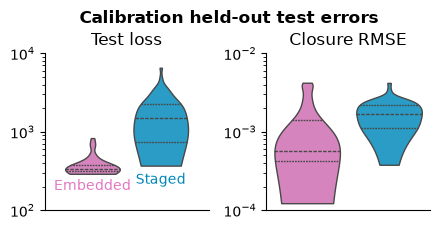

In [14]:
# =============================================================================
# Figure: calibration held-out test loss and calibration closure RMSE
# =============================================================================

def plot_calibration_test_loss_and_closure_rmse_violins(calibration_test_metrics_df, *, filename_stem="violin_calibration_test_loss_and_closure_rmse", log_y=True, inner="quartile"):
    fig, axs = plt.subplots(1, 2, figsize=(4.5,2.5), sharex=False)

    panel_specs = [
        {"ax": axs[0], "df": calibration_test_metrics_df, "metric": "Test loss", "title": "Test loss"},
        {"ax": axs[1], "df": calibration_test_metrics_df, "metric": "Closure RMSE", "title": "Closure RMSE"},
    ]

    final_handles = None
    final_labels = None

    for spec in panel_specs:
        ax = spec["ax"]
        df = spec["df"]
        metric = spec["metric"]

        plot_df = df[(df["metric"] == metric) & np.isfinite(df["value"])].copy()

        if log_y:
            plot_df = plot_df[plot_df["value"] > 0].copy()

        if plot_df.empty:
            raise RuntimeError(f"No finite data to plot for metric={metric}.")

        violinplot_only(data=plot_df, x="method", y="value", hue="method", order=METHOD_ORDER, hue_order=METHOD_ORDER, palette=METHOD_PALETTE, inner=inner, ax=ax)

        if log_y:
            ax.set_yscale("log")

        ax.set_title(spec["title"])
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_xticks([])
        ax.spines[["top", "right"]].set_visible(False)

        if ax.legend_ is not None:
            ax.legend_.remove()

    axs[0].set_yticks([1e2,1e3,1e4])
    axs[1].set_yticks([1e-2,1e-3, 1e-4])

    axs[0].annotate('Embedded', (0,2.5e2), ha='center', va='top', color='C6')
    axs[0].annotate('Staged', (1,3e2), ha='center', va='top', color="#0087b8")
    axs[0].set_xlim([-.7,1.7])

    fig.suptitle("Calibration held-out test errors", y=.90, x=0.52, fontweight="bold")
    fig.tight_layout()

    save_figure(fig, filename_stem)

    return fig, axs


fig, axs = plot_calibration_test_loss_and_closure_rmse_violins(calibration_test_metrics_df, filename_stem="violin_calibration_test_loss_and_closure_rmse", log_y=True, inner="quartile")

# Calibration and validation scenario trajectories in the \(s\)-\(i\) plane

In [15]:
cal_scenario = calibration_scenario()
val_scenarios = validation_scenarios()

scenario_list = [cal_scenario] + val_scenarios
scenario_labels = [
    "calibration",
    "validation 1",
    "validation 2",
    "validation 3",
]

# Use the same time grid as the saved study observations.
t_eval = t_obs_ref

scenario_y = {}
scenario_xi = {}

for label, scenario in zip(scenario_labels, scenario_list):
    y = simulate_true_siqr(
        scenario=scenario,
        config=obs_config,
        t_eval=t_eval,
    )
    xi = xi_f_nondim(
        y,
        N_total=obs_config.N_total,
        threshold_count=obs_config.xi_threshold_count,
        transition_width_fraction=obs_config.xi_transition_width_fraction,
    )
    scenario_y[label] = y
    scenario_xi[label] = xi

Saved figures/s-i_scenario_projection.png


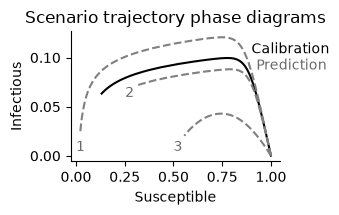

In [16]:
fig, ax = plt.subplots(figsize=(3.5,2.25))

colors = ["black", "C0", "C1", "C2"]
linestyles = ["-", "-", "-", "-"]

for scenario_label, y in scenario_y.items():
    linestyle = '-' if scenario_label=='calibration' else '--'
    color = 'k' if scenario_label=='calibration' else 'grey'
    ax.plot(y[0,:], y[1,:], color=color, linestyle=linestyle)

ax.annotate("Calibration", (0.9,0.101), va='bottom')
ax.annotate("Prediction", (0.925,0.099), va='top', color='dimgrey')
ax.annotate("1", (0.,0.005), color='dimgrey')
ax.annotate("2", (0.252,0.06), color='dimgrey')
ax.annotate("3", (0.5,0.005), color='dimgrey')

ax.spines[['top','right']].set_visible(False)
ax.set_xlabel(r"Susceptible")
ax.set_ylabel(r"Infectious")
ax.set_title("Scenario trajectory phase diagrams")
fig.tight_layout()
save_figure(fig, "s-i_scenario_projection")

# Validation generalization results

This section loads saved outputs from:

- `staged_generalization.npz`
- `embedded_generalization.npz`

and compares embedded and STAGED DDCM validation errors and rollout traces.

In [17]:
# =============================================================================
# Load saved embedded and staged generalization outputs
# =============================================================================

def _as_str_array(arr):
    """
    Convert a NumPy string/bytes/object array to a list of Python strings.
    """
    arr = np.asarray(arr)

    out = []
    for item in arr:
        if isinstance(item, bytes):
            out.append(item.decode("utf-8"))
        else:
            out.append(str(item))

    return out


def load_saved_generalization_outputs(
    study_dir,
    method: str,
    num_replicates=NUM_REPLICATES_REQUESTED,
    require_overall_success=False,
):
    """
    Load per-replicate generalization predictions.

    method:
        "embedded" or "staged"

    Expected files:
        rep_XXX/embedded_generalization.npz
        rep_XXX/staged_generalization.npz
    """
    if method not in ["staged", "embedded"]:
        raise ValueError("method must be either 'staged' or 'embedded'.")

    study_dir = Path(study_dir)
    filename = f"{method}_generalization.npz"

    rep_ids = []
    xi_pred_list = []
    y_pred_list = []
    scenario_success_list = []
    state_rmse_list = []
    closure_rmse_list = []

    reference = None

    for r in range(num_replicates):
        gen_file = study_dir / f"rep_{r:03d}" / filename

        if not gen_file.exists():
            print(f"Skipping {method} rep {r:03d}: missing {filename}")
            continue

        try:
            z = np.load(gen_file, allow_pickle=True)

            overall_success = bool(np.asarray(z["success"]).item())

            if require_overall_success and not overall_success:
                print(f"Skipping {method} rep {r:03d}: success=False")
                continue

            scenario_names = _as_str_array(z["scenario_names"])
            scenario_params = np.asarray(z["scenario_params"], dtype=float)
            t_eval = np.asarray(z["t_eval"], dtype=float)

            xi_true = np.asarray(z["xi_true"], dtype=float)
            y_true = np.asarray(z["y_true"], dtype=float)

            xi_pred = np.asarray(z["xi_pred"], dtype=float)
            y_pred = np.asarray(z["y_pred"], dtype=float)

            scenario_success = np.asarray(z["scenario_success"], dtype=bool)
            state_rmse = np.asarray(z["state_rmse"], dtype=float)
            closure_rmse = np.asarray(z["closure_rmse"], dtype=float)

            if reference is None:
                reference = {
                    "scenario_names": scenario_names,
                    "scenario_params": scenario_params,
                    "t_eval": t_eval,
                    "xi_true": xi_true,
                    "y_true": y_true,
                }
            else:
                if scenario_names != reference["scenario_names"]:
                    raise ValueError(
                        f"Scenario names differ for {method} rep {r:03d}. "
                        f"Expected {reference['scenario_names']}, got {scenario_names}."
                    )

                if not np.allclose(t_eval, reference["t_eval"]):
                    raise ValueError(f"t_eval differs for {method} rep {r:03d}.")

            rep_ids.append(r)
            xi_pred_list.append(xi_pred)
            y_pred_list.append(y_pred)
            scenario_success_list.append(scenario_success)
            state_rmse_list.append(state_rmse)
            closure_rmse_list.append(closure_rmse)

        except Exception as exc:
            print(f"Skipping {method} rep {r:03d}: failed to load because {exc}")

    if len(rep_ids) == 0:
        raise RuntimeError(
            f"No {method} generalization outputs loaded from {study_dir}."
        )

    return {
        "method": method,
        "rep_ids": np.asarray(rep_ids, dtype=int),
        "scenario_names": reference["scenario_names"],
        "scenario_params": reference["scenario_params"],
        "t_eval": reference["t_eval"],
        "xi_true": reference["xi_true"],
        "y_true": reference["y_true"],
        "xi_pred": np.asarray(xi_pred_list, dtype=float),
        "y_pred": np.asarray(y_pred_list, dtype=float),
        "scenario_success": np.asarray(scenario_success_list, dtype=bool),
        "state_rmse": np.asarray(state_rmse_list, dtype=float),
        "closure_rmse": np.asarray(closure_rmse_list, dtype=float),
    }


staged_gen = load_saved_generalization_outputs(
    study_dir=STUDY_DIR,
    method="staged",
    num_replicates=NUM_REPLICATES_REQUESTED,
    require_overall_success=False,
)

embedded_gen = load_saved_generalization_outputs(
    study_dir=STUDY_DIR,
    method="embedded",
    num_replicates=NUM_REPLICATES_REQUESTED,
    require_overall_success=False,
)

common_generalization_reps = sorted(
    set(staged_gen["rep_ids"]).intersection(set(embedded_gen["rep_ids"]))
)

print()
print(f"Loaded staged generalization predictions for {len(staged_gen['rep_ids'])} replicates.")
print(f"Loaded embedded generalization predictions for {len(embedded_gen['rep_ids'])} replicates.")
print(f"Common staged+embedded generalization reps: {len(common_generalization_reps)}")
print("Validation scenarios:", staged_gen["scenario_names"])


Loaded staged generalization predictions for 50 replicates.
Loaded embedded generalization predictions for 50 replicates.
Common staged+embedded generalization reps: 50
Validation scenarios: ['val1', 'val2', 'val3']


### Plotting validation time histories

In [18]:
# =============================================================================
# Helper: successful traces for one validation scenario
# =============================================================================

def successful_traces_for_scenario(gen, array_key, scenario_idx):
    success_mask = np.asarray(gen["scenario_success"][:, scenario_idx], dtype=bool)
    arr = np.asarray(gen[array_key], dtype=float)
    return arr[success_mask, scenario_idx, ...]


if staged_gen["scenario_names"] != embedded_gen["scenario_names"]:
    raise ValueError("Scenario names differ between staged and embedded generalization outputs.")

if not np.allclose(staged_gen["t_eval"], embedded_gen["t_eval"]):
    raise ValueError("t_eval differs between staged and embedded generalization outputs.")

if not np.allclose(staged_gen["xi_true"], embedded_gen["xi_true"]):
    warnings.warn("xi_true differs between staged and embedded outputs. Using staged_gen['xi_true'] for plotting.")

if not np.allclose(staged_gen["y_true"], embedded_gen["y_true"]):
    warnings.warn("y_true differs between staged and embedded outputs. Using staged_gen['y_true'] for plotting.")

Saved figures/embedded_staged_validation_closures.png


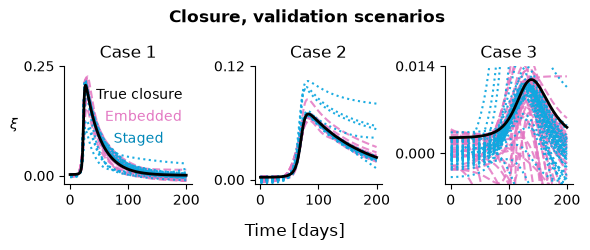

In [19]:
# =============================================================================
# Figure: closure traces, validation scenarios, embedded vs staged
# =============================================================================

t_eval = staged_gen["t_eval"]
xi_true = staged_gen["xi_true"]
scenario_names = staged_gen["scenario_names"]

ylims = [(-0.02, 0.25), (-0.005, 0.12), (-0.005, 0.014)]

fig, axs = plt.subplots(1, len(scenario_names), figsize=(6, 2.25), sharex=True)

if len(scenario_names) == 1:
    axs = [axs]

for i, (scenario_name, ax, ylim) in enumerate(zip(scenario_names, axs, ylims)):
    title = f"Case {scenario_name.split('val')[-1]}"
    ax.set_title(title)


    embedded_xi_i = successful_traces_for_scenario(embedded_gen, array_key="xi_pred", scenario_idx=i)
    staged_xi_i = successful_traces_for_scenario(staged_gen, array_key="xi_pred", scenario_idx=i)

    if embedded_xi_i.shape[0] > 0:
        ax.plot(t_eval, embedded_xi_i.T, "--", color="C6", lw=1.5, alpha=0.85)

    if staged_xi_i.shape[0] > 0:
        ax.plot(t_eval, staged_xi_i.T, ":", color="#10a8e0", lw=1.5, alpha=0.95)

    ax.plot(t_eval, xi_true[i], "k", lw=2)

    ax.set_ylim(ylim)

    ax.set_yticks([0, ax.get_ylim()[1]])
    ax.spines[["top", "right"]].set_visible(False)

axs[0].set_ylabel(r"$\xi$", rotation=0, ha="right", va="center")

axs[0].annotate("True closure", (45,0.2), va="top", ha="left", annotation_clip=False)
axs[0].annotate("Embedded", (60,0.15), va="top", ha="left", annotation_clip=False, color="C6")
axs[0].annotate("Staged", (75, 0.1), va="top", ha="left", annotation_clip=False, color="#0087b8")

fig.suptitle("Closure, validation scenarios", y=0.95, x=0.52, fontweight="bold")
fig.text(0.5, 0, "Time [days]", ha="center", va="top", fontsize=12)

fig.tight_layout(w_pad=0.4)

save_figure(fig, "embedded_staged_validation_closures")

Saved figures/embedded_staged_population_ratios_validation_scenarios.png


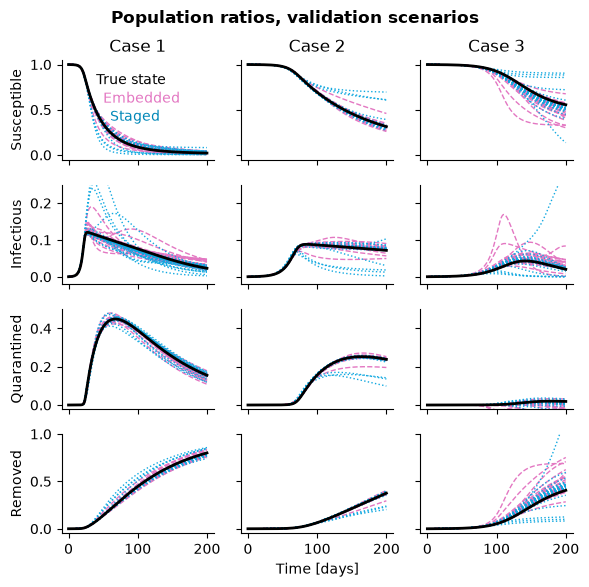

In [20]:
# =============================================================================
# Figure: state traces, validation scenarios, embedded vs staged
# =============================================================================

t_eval = staged_gen["t_eval"]
y_true = staged_gen["y_true"]
scenario_names = staged_gen["scenario_names"]

fig, axs = plt.subplots(4, len(scenario_names), figsize=(6, 6), sharex=True, sharey="row")

if len(scenario_names) == 1:
    axs = axs.reshape(4, 1)


for i, (scenario_name) in enumerate(scenario_names):
    title = f"Case {scenario_name.split('val')[-1]}"
    axs[0, i].set_title(title)

    embedded_y_i = successful_traces_for_scenario(embedded_gen, array_key="y_pred", scenario_idx=i)
    staged_y_i = successful_traces_for_scenario(staged_gen, array_key="y_pred", scenario_idx=i)

    for j in range(4):
        ax = axs[j, i]


        if embedded_y_i.shape[0] > 0:
            ax.plot(t_eval, embedded_y_i[:, :, j].T, "--", color="C6", lw=1)

        if staged_y_i.shape[0] > 0:
            ax.plot(t_eval, staged_y_i[:, :, j].T, ":", color="#10a8e0", lw=1)

        ax.plot(t_eval, y_true[i, :, j], "k", lw=2)
        ax.spines[["top", "right"]].set_visible(False)

for ax, sn in zip(axs[:, 0], STATE_NAMES):
    ax.set_ylabel(sn)

axs[-1, len(scenario_names) // 2].set_xlabel("Time [days]")

axs[0, 0].annotate("True state", (40, 0.9), va="top", ha="left", annotation_clip=False)
axs[0, 0].annotate("Embedded", (50, 0.7), va="top", ha="left", annotation_clip=False, color="C6")
axs[0, 0].annotate("Staged", (60, 0.5), va="top", ha="left", annotation_clip=False, color="#0087b8")

ylims = [(-0.05, 1.05), (-0.02, 0.25), (-0.02, 0.5), (-0.05, 1)]
for ax, ylim in zip(axs, ylims):
    ax[0].set_ylim(ylim)

fig.suptitle("Population ratios, validation scenarios", y=0.97, fontweight="bold")

fig.tight_layout()

save_figure(fig, "embedded_staged_population_ratios_validation_scenarios")

### Plotting RMSE

In [21]:
# =============================================================================
# Build validation/generalization state-RMSE and closure-RMSE dataframe
# =============================================================================

def build_validation_metrics_df(embedded_gen, staged_gen):
    """
    Long-form dataframe for validation scenario metrics.

    Metrics:
        - State RMSE
        - Closure RMSE
    """
    rows = []

    for gen, method_label in [
        (embedded_gen, "Embedded"),
        (staged_gen, "STAGED DDCM"),
    ]:
        rep_ids = np.asarray(gen["rep_ids"], dtype=int)
        scenario_names = list(gen["scenario_names"])
        success = np.asarray(gen["scenario_success"], dtype=bool)

        state_rmse = np.asarray(gen["state_rmse"], dtype=float)
        closure_rmse = np.asarray(gen["closure_rmse"], dtype=float)

        for r_idx, r in enumerate(rep_ids):
            for s_idx, scenario_name in enumerate(scenario_names):
                if not success[r_idx, s_idx]:
                    continue

                rows.append(
                    {
                        "replicate": int(r),
                        "method": method_label,
                        "scenario": str(scenario_name),
                        "metric": "State RMSE",
                        "value": float(state_rmse[r_idx, s_idx]),
                    }
                )

                rows.append(
                    {
                        "replicate": int(r),
                        "method": method_label,
                        "scenario": str(scenario_name),
                        "metric": "Closure RMSE",
                        "value": float(closure_rmse[r_idx, s_idx]),
                    }
                )

    return pd.DataFrame(rows)


validation_metrics_df = build_validation_metrics_df(
    embedded_gen=embedded_gen,
    staged_gen=staged_gen,
)

display(validation_metrics_df.head())

print(
    validation_metrics_df
    .groupby(["scenario", "metric", "method"])["value"]
    .describe()
)

,replicate,method,scenario,metric,value
0,0,Embedded,val1,State RMSE,0.005301
1,0,Embedded,val1,Closure RMSE,0.004126
2,0,Embedded,val2,State RMSE,0.003132
3,0,Embedded,val2,Closure RMSE,0.002274
4,0,Embedded,val3,State RMSE,0.006363


                                   count      mean       std       min  \
scenario metric       method                                             
val1     Closure RMSE Embedded      50.0  0.005093  0.003717  0.001945   
                      STAGED DDCM   50.0  0.005742  0.007193  0.001419   
         State RMSE   Embedded      50.0  0.009429  0.007848  0.001464   
                      STAGED DDCM   50.0  0.011483  0.016523  0.002939   
val2     Closure RMSE Embedded      50.0  0.001688  0.001758  0.000410   
                      STAGED DDCM   50.0  0.003886  0.006351  0.000625   
         State RMSE   Embedded      50.0  0.004298  0.007452  0.000935   
                      STAGED DDCM   50.0  0.009924  0.021837  0.000917   
val3     Closure RMSE Embedded      50.0  0.005201  0.006359  0.000464   
                      STAGED DDCM   50.0  0.007249  0.012511  0.000955   
         State RMSE   Embedded      50.0  0.019356  0.032557  0.000826   
                      STAGED DDCM   50

Saved figures/validation_error_violin_plots.png


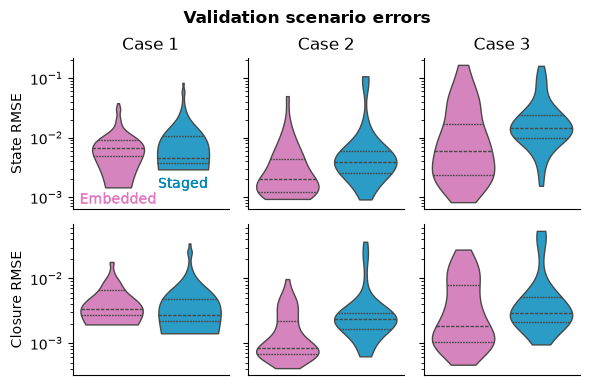

In [22]:
# =============================================================================
# Figure builder: validation state RMSE and closure RMSE, separated by scenario
# =============================================================================

def make_validation_state_and_closure_rmse_by_scenario_violins(validation_metrics_df, *, log_y=True, inner="quartile"):
    validation_scenarios = list(staged_gen["scenario_names"])

    fig, axs = plt.subplots(2, len(validation_scenarios), figsize=(6, 4), sharex=False, sharey="row")

    if len(validation_scenarios) == 1:
        axs = axs.reshape(2, 1)

    row_specs = [
        {"row": 0, "metric": "State RMSE", "ylabel": "State RMSE"},
        {"row": 1, "metric": "Closure RMSE", "ylabel": "Closure RMSE"},
    ]

    final_handles = None
    final_labels = None

    for col, scenario in enumerate(validation_scenarios):
        scenario_title = f"Case {scenario.split('val')[-1]}"

        for row_spec in row_specs:
            row = row_spec["row"]
            metric = row_spec["metric"]
            ax = axs[row, col]

            plot_df = validation_metrics_df[(validation_metrics_df["metric"] == metric) & (validation_metrics_df["scenario"] == scenario) & np.isfinite(validation_metrics_df["value"])].copy()

            if log_y:
                plot_df = plot_df[plot_df["value"] > 0].copy()

            if plot_df.empty:
                raise RuntimeError(f"No finite data to plot for scenario={scenario}, metric={metric}.")

            violinplot_only(data=plot_df, x="method", y="value", hue="method", order=METHOD_ORDER, hue_order=METHOD_ORDER, palette=METHOD_PALETTE, inner=inner, ax=ax)

            if log_y:
                ax.set_yscale("log")

            if row == 0:
                ax.set_title(scenario_title)

            if col == 0:
                ax.set_ylabel(row_spec["ylabel"])
            else:
                ax.set_ylabel("")

            ax.set_xlabel("")
            ax.set_xticks([])
            ax.spines[["top", "right"]].set_visible(False)

            handles, labels = ax.get_legend_handles_labels()
            final_handles = handles[:len(METHOD_ORDER)]
            final_labels = labels[:len(METHOD_ORDER)]

            if ax.legend_ is not None:
                ax.legend_.remove()
        axs[0,0].annotate('Embedded', (0,1.2e-3), ha='center', va='top', color='C6')
        axs[0,0].annotate('Staged', (1,2.2e-3), ha='center', va='top', color="#0087b8")
        axs[0,0].set_xlim([-.7,1.7])

    fig.suptitle("Validation scenario errors", y=0.95, x=0.52, fontweight="bold")
    fig.tight_layout()

    return fig, axs, final_handles, final_labels

fig, axs, handles, labels = make_validation_state_and_closure_rmse_by_scenario_violins(validation_metrics_df, log_y=True, inner="quartile")
save_figure(fig, 'validation_error_violin_plots')

# Accuracy and cost tables

In [23]:
# =============================================================================
# Load training-cost and robustness metrics needed by tables
# =============================================================================

def get_embedded_training_model_evals(r: int):
    """
    Embedded training-procedure model/loss evaluations.
    """
    path = rep_dir(r) / "embedded_closure.npz"

    if not path.exists():
        return np.nan

    z = np.load(path, allow_pickle=True)

    if "num_eval" in z.files:
        return float(np.asarray(z["num_eval"]))

    return np.nan


def get_staged_model_eval_components(r: int):
    """
    STAGED model-evaluation accounting.

    Returns:
        final EnKF assimilation model evaluations,
        process-noise MLE model evaluations,
        total model evaluations.
    """
    path = rep_dir(r) / "enkf_result.npz"

    if not path.exists():
        return {
            "enkf_model_evaluations": np.nan,
            "mle_model_evaluations": np.nan,
            "total_model_evaluations": np.nan,
        }

    z = np.load(path, allow_pickle=True)

    enkf_eval = (
        float(np.asarray(z["model_evaluations"]))
        if "model_evaluations" in z.files
        else np.nan
    )

    mle_eval = (
        float(np.asarray(z["mle_model_evaluations"]))
        if "mle_model_evaluations" in z.files
        else np.nan
    )

    total_eval = (
        float(np.asarray(z["total_model_evaluations"]))
        if "total_model_evaluations" in z.files
        else np.nan
    )

    if not np.isfinite(total_eval) and np.isfinite(enkf_eval):
        warnings.warn(
            f"rep {r:03d}: missing total_model_evaluations; "
            "falling back to model_evaluations only."
        )
        total_eval = enkf_eval

    return {
        "enkf_model_evaluations": enkf_eval,
        "mle_model_evaluations": mle_eval,
        "total_model_evaluations": total_eval,
    }


def get_staged_training_model_evals(r: int):
    return get_staged_model_eval_components(r)["total_model_evaluations"]


def get_bad_starts_from_closure(r: int, method: str):
    path = rep_dir(r) / f"{method}_closure.npz"

    if not path.exists():
        return np.nan

    z = np.load(path, allow_pickle=True)

    if "bad_starts" in z.files:
        return float(np.asarray(z["bad_starts"]))

    return np.nan


common_reps = get_common_successful_training_reps()

embedded_eval = []
staged_eval = []
staged_enkf_eval = []
staged_mle_eval = []
embedded_bad = []
staged_bad = []

for r in common_reps:
    embedded_eval.append(get_embedded_training_model_evals(r))
    staged_eval.append(get_staged_training_model_evals(r))

    components = get_staged_model_eval_components(r)
    staged_enkf_eval.append(components["enkf_model_evaluations"])
    staged_mle_eval.append(components["mle_model_evaluations"])

    embedded_bad.append(get_bad_starts_from_closure(r, "embedded"))
    staged_bad.append(get_bad_starts_from_closure(r, "staged"))

embedded_eval = np.asarray(embedded_eval, dtype=float)
staged_eval = np.asarray(staged_eval, dtype=float)
staged_enkf_eval = np.asarray(staged_enkf_eval, dtype=float)
staged_mle_eval = np.asarray(staged_mle_eval, dtype=float)
embedded_bad = np.asarray(embedded_bad, dtype=float)
staged_bad = np.asarray(staged_bad, dtype=float)

print("Loaded cost/robustness metrics")
print(f"Common training replicates: {len(common_reps)}")
print(f"Embedded evals mean ± std: {np.nanmean(embedded_eval):.2f} ± {np.nanstd(embedded_eval):.2f}")
print(f"STAGED evals mean ± std:   {np.nanmean(staged_eval):.2f} ± {np.nanstd(staged_eval):.2f}")
print(f"Embedded bad starts total: {np.nansum(embedded_bad):.0f}")
print(f"STAGED bad starts total:   {np.nansum(staged_bad):.0f}")

Loaded cost/robustness metrics
Common training replicates: 50
Embedded evals mean ± std: 24079.48 ± 7414.29
STAGED evals mean ± std:   2782.00 ± 358.71
Embedded bad starts total: 215
STAGED bad starts total:   0


In [24]:
# =============================================================================
# Summary statistics for plotted calibration and validation metrics
# =============================================================================

combined_metric_df = pd.concat(
    [
        calibration_test_metrics_df,
        validation_metrics_df,
    ],
    ignore_index=True,
)

metric_summary_table = (
    combined_metric_df
    .groupby(["scenario", "metric", "method"])["value"]
    .agg(
        num_replicates="count",
        mean="mean",
        std="std",
        median="median",
        q25=lambda x: np.quantile(x, 0.25),
        q75=lambda x: np.quantile(x, 0.75),
    )
    .reset_index()
)

display(metric_summary_table)

summary_file = FIG_DIR / "test_loss_closure_and_validation_error_summary.csv"
metric_summary_table.to_csv(summary_file, index=False)

print(f"Saved {summary_file}")

,scenario,metric,method,num_replicates,mean,std,median,q25,q75
0,Calibration test,Closure RMSE,Embedded,50,0.001175,0.001183,0.000565,0.000428,0.001428
1,Calibration test,Closure RMSE,STAGED DDCM,50,0.001702,0.000750,0.001701,0.001116,0.002213
2,Calibration test,Test loss,Embedded,50,392.210366,136.454657,333.431641,317.012077,375.319794
3,Calibration test,Test loss,STAGED DDCM,50,1754.676132,1241.515974,1494.258450,736.329422,2273.330382
4,val1,Closure RMSE,Embedded,50,0.005093,0.003717,0.003364,0.002676,0.006617
5,val1,Closure RMSE,STAGED DDCM,50,0.005742,0.007193,0.002763,0.002163,0.004787
6,val1,State RMSE,Embedded,50,0.009429,0.007848,0.006653,0.005009,0.009258
7,val1,State RMSE,STAGED DDCM,50,0.011483,0.016523,0.004500,0.003774,0.010571
8,val2,Closure RMSE,Embedded,50,0.001688,0.001758,0.000838,0.000680,0.002191
9,val2,Closure RMSE,STAGED DDCM,50,0.003886,0.006351,0.002323,0.001646,0.002957


Saved figures/test_loss_closure_and_validation_error_summary.csv


In [25]:
# =============================================================================
# Manuscript-style summary table using current plotted metrics
# =============================================================================

def get_metric_mean_std(df, *, scenario, metric, method):
    vals = df[
        (df["scenario"] == scenario)
        & (df["metric"] == metric)
        & (df["method"] == method)
    ]["value"].to_numpy(dtype=float)

    return nanmean_std(vals)


embedded_test_loss_mean, embedded_test_loss_std = get_metric_mean_std(
    calibration_test_metrics_df,
    scenario="Calibration test",
    metric="Test loss",
    method="Embedded",
)

staged_test_loss_mean, staged_test_loss_std = get_metric_mean_std(
    calibration_test_metrics_df,
    scenario="Calibration test",
    metric="Test loss",
    method="STAGED DDCM",
)

embedded_closure_mean, embedded_closure_std = get_metric_mean_std(
    calibration_test_metrics_df,
    scenario="Calibration test",
    metric="Closure RMSE",
    method="Embedded",
)

staged_closure_mean, staged_closure_std = get_metric_mean_std(
    calibration_test_metrics_df,
    scenario="Calibration test",
    metric="Closure RMSE",
    method="STAGED DDCM",
)

embedded_eval_mean, embedded_eval_std = nanmean_std(embedded_eval)
staged_eval_mean, staged_eval_std = nanmean_std(staged_eval)

embedded_bad_total = int(np.nansum(embedded_bad))
staged_bad_total = int(np.nansum(staged_bad))

summary_table = pd.DataFrame(
    [
        {
            "Method": "Embedded",
            "Test loss mean": embedded_test_loss_mean,
            "Test loss std": embedded_test_loss_std,
            "Calibration closure RMSE mean": embedded_closure_mean,
            "Calibration closure RMSE std": embedded_closure_std,
            "Training model evals mean": embedded_eval_mean,
            "Training model evals std": embedded_eval_std,
            "Bad starts total": embedded_bad_total,
        },
        {
            "Method": "STAGED DDCM",
            "Test loss mean": staged_test_loss_mean,
            "Test loss std": staged_test_loss_std,
            "Calibration closure RMSE mean": staged_closure_mean,
            "Calibration closure RMSE std": staged_closure_std,
            "Training model evals mean": staged_eval_mean,
            "Training model evals std": staged_eval_std,
            "Bad starts total": staged_bad_total,
        },
    ]
)

display(summary_table)

summary_file = FIG_DIR / "manuscript_summary_table.csv"
summary_table.to_csv(summary_file, index=False)

print(f"Saved {summary_file}")

,Method,Test loss mean,Test loss std,Calibration closure RMSE mean,Calibration closure RMSE std,Training model evals mean,Training model evals std,Bad starts total
0,Embedded,392.210366,135.083219,0.001175,0.001171,24079.48,7414.288992,215
1,STAGED DDCM,1754.676132,1229.038110,0.001702,0.000742,2782.00,358.714371,0


Saved figures/manuscript_summary_table.csv


In [26]:
# =============================================================================
# LaTeX table: calibration test loss, closure RMSE, cost, and robustness
# =============================================================================

accuracy_cost_lines = [
    r"\begin{table}[t]",
    r"\centering",
    r"\caption{Comparison of embedded and STAGED DDCM methods over 50 replicates. "
    r"Calibration performance is reported using the held-out observation-space test loss "
    r"and synthetic closure RMSE on the calibration test indices. Scalability is measured "
    r"by training-stage model evaluations. For the embedded method, this corresponds to "
    r"Neural ODE loss/evaluation calls. For STAGED DDCM, this includes process-noise MLE "
    r"model evaluations and final EnKF assimilation model evaluations. Robustness is "
    r"measured by the total number of failed neural-network starts.}",
    r"\label{tab:accuracy_cost_robustness}",
    r"\begin{tabular}{lcccc}",
    r"\hline",
    r"Method & Test loss & Closure RMSE & Training model evaluations & Failed starts \\",
    r"\hline",
    (
        rf"Embedded & "
        rf"{tex_pm(embedded_test_loss_mean, embedded_test_loss_std)} & "
        rf"{tex_pm(embedded_closure_mean, embedded_closure_std)} & "
        rf"{tex_pm(embedded_eval_mean, embedded_eval_std)} & "
        rf"{embedded_bad_total} \\"
    ),
    (
        rf"STAGED DDCM & "
        rf"{tex_pm(staged_test_loss_mean, staged_test_loss_std)} & "
        rf"{tex_pm(staged_closure_mean, staged_closure_std)} & "
        rf"{tex_pm(staged_eval_mean, staged_eval_std)} & "
        rf"{staged_bad_total} \\"
    ),
    r"\hline",
    r"\end{tabular}",
    r"\end{table}",
]

accuracy_cost_tex = write_tex_table(
    TABLE_DIR / "accuracy_cost_robustness_table.tex",
    accuracy_cost_lines,
)

print(accuracy_cost_tex)

Saved tables/accuracy_cost_robustness_table.tex
\begin{table}[t]
\centering
\caption{Comparison of embedded and STAGED DDCM methods over 50 replicates. Calibration performance is reported using the held-out observation-space test loss and synthetic closure RMSE on the calibration test indices. Scalability is measured by training-stage model evaluations. For the embedded method, this corresponds to Neural ODE loss/evaluation calls. For STAGED DDCM, this includes process-noise MLE model evaluations and final EnKF assimilation model evaluations. Robustness is measured by the total number of failed neural-network starts.}
\label{tab:accuracy_cost_robustness}
\begin{tabular}{lcccc}
\hline
Method & Test loss & Closure RMSE & Training model evaluations & Failed starts \\
\hline
Embedded & \(3.92\times 10^{2}\) \( \pm \) \(1.35\times 10^{2}\) & \(1.18\times 10^{-3}\) \( \pm \) \(1.17\times 10^{-3}\) & \(2.41\times 10^{4}\) \( \pm \) \(7.41\times 10^{3}\) & 215 \\
STAGED DDCM & \(1.75\times 10^

In [27]:
# =============================================================================
# LaTeX table: STAGED model-evaluation accounting breakdown
# =============================================================================

staged_enkf_eval_mean, staged_enkf_eval_std = nanmean_std(staged_enkf_eval)
staged_mle_eval_mean, staged_mle_eval_std = nanmean_std(staged_mle_eval)
staged_total_eval_mean, staged_total_eval_std = nanmean_std(staged_eval)

staged_breakdown_lines = [
    r"\begin{table}[t]",
    r"\centering",
    r"\caption{STAGED DDCM training-stage model-evaluation accounting. "
    r"The total is the sum of process-noise MLE model evaluations and final EnKF "
    r"assimilation model evaluations. The subsequent supervised neural-network "
    r"training stage is offline and does not invoke the SIQR simulator.}",
    r"\label{tab:staged_model_eval_breakdown}",
    r"\begin{tabular}{lc}",
    r"\hline",
    r"Component & Model evaluations \\",
    r"\hline",
    (
        rf"Process-noise MLE & "
        rf"{tex_pm(staged_mle_eval_mean, staged_mle_eval_std)} \\"
    ),
    (
        rf"Final EnKF assimilation & "
        rf"{tex_pm(staged_enkf_eval_mean, staged_enkf_eval_std)} \\"
    ),
    (
        rf"Total STAGED DDCM & "
        rf"{tex_pm(staged_total_eval_mean, staged_total_eval_std)} \\"
    ),
    r"\hline",
    r"\end{tabular}",
    r"\end{table}",
]

staged_breakdown_tex = write_tex_table(
    TABLE_DIR / "staged_model_eval_breakdown_table.tex",
    staged_breakdown_lines,
)

print(staged_breakdown_tex)

Saved tables/staged_model_eval_breakdown_table.tex
\begin{table}[t]
\centering
\caption{STAGED DDCM training-stage model-evaluation accounting. The total is the sum of process-noise MLE model evaluations and final EnKF assimilation model evaluations. The subsequent supervised neural-network training stage is offline and does not invoke the SIQR simulator.}
\label{tab:staged_model_eval_breakdown}
\begin{tabular}{lc}
\hline
Component & Model evaluations \\
\hline
Process-noise MLE & \(2.68\times 10^{3}\) \( \pm \) \(3.59\times 10^{2}\) \\
Final EnKF assimilation & \(1.00\times 10^{2}\) \( \pm \) \(0\) \\
Total STAGED DDCM & \(2.78\times 10^{3}\) \( \pm \) \(3.59\times 10^{2}\) \\
\hline
\end{tabular}
\end{table}

